# 5. The filter's measurement model

> Evaluate the tracking data against the reference trajectory: pre-fit residuals, measurement partials, and the linearized measurement equation the filter solves. Package everything for the filter with `MeasurementSpec`.
>
> ⏱ ~10 min &nbsp;·&nbsp; 
**Prereqs:** [3. Tracking data I](03_tracking_data.ipynb), [4. The filter's dynamics model](04_filter_dynamics.ipynb) &nbsp;·&nbsp; 
**Uses:** `outputs/02_truth_dynamics/truth.bsp`, `outputs/03_tracking_data/*.json` &nbsp;·&nbsp; 
**Next:** [6. First OD solution](06_first_od_solution.ipynb)

For each observation $z_k$, a linearized filter needs the pre-fit residual $y_k = z_k - h(x^*(t_k))$ against the reference $x^*$, and the measurement partials $\tilde H_k = \partial h / \partial x$ evaluated on the reference. Mapped back to the epoch through the STM, these give the linearized measurement equation

$$ y_k \approx \tilde H_k\,\Phi(t_k, t_0)\,\delta x_0 + \epsilon_k, $$

which is what the filters in chapters [6](06_first_od_solution.ipynb) and [7](07_sequential_filtering.ipynb) solve for $\delta x_0$. This chapter computes each term with the same measurement model objects used to simulate the data.

## Setup

The scenario, imported from [`scenario.py`](scenario.py): the filter's dynamics model from [chapter 4](04_filter_dynamics.ipynb) (reference spacecraft and a-priori state; the reference is propagated again here, with its STM), and the measurement models from [chapter 3](03_tracking_data.ipynb). The truth is loaded only to evaluate the linearized measurement equation with the known initial deviation.

**Starting here?** This chapter reads the outputs of chapters [2](02_truth_dynamics.ipynb) and [3](03_tracking_data.ipynb). Run `python prepare.py 05` from `tutorials/v2/` to generate them (about 15 s); the setup cell stops with a message if they are missing.

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import scarabaeus as scb

from scenario import (
    kg, km, m, mm, sec, minute, day, J2000, sun,  # units, frame, central body
    epochs, orex, planets,                        # tracking arc, truth spacecraft, third bodies (ch. 1-2)
    stations, models, TRACKING_DIR,               # measurement models and their data (ch. 3)
    reference, r_apriori, v_apriori,              # the filter's spacecraft and a-priori state (ch. 4)
    apriori_state as state, reference_propagator,
)

out = Path("outputs/05_filter_measurements")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)
tracking_dir = Path(TRACKING_DIR)  # produced by chapter 3

# Inputs from earlier chapters. Starting here? Run `python prepare.py 05` first.
if not (
    Path("outputs/02_truth_dynamics/truth.bsp").exists()
    and len(list(tracking_dir.glob("*.json"))) == 6
):
    raise FileNotFoundError(
        "This chapter reads the truth trajectory (chapter 2) and the tracking data (chapter 3). "
        "Run those chapters, or `python prepare.py 05` from tutorials/v2/ (about 15 s)."
    )

scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")  # truth (ch. 2)
days = (epochs - epochs[0]).convert_to(day).values

# --- the reference trajectory and its STM (chapter 4) ---
x_truth0 = orex.get_state(epochs[0], reference_frame="J2000", origin="SUN")
propagator = reference_propagator()
propagator.propagate()
scb.Trajectory(state_array=propagator.propagated_state_array).write_to_spk(str(out / "reference.bsp"))
scb.SpiceManager.load_kernel(str(out / "reference.bsp"))
Phi = propagator.STM.quantity.values.reshape(-1, 6, 6)


## 1. Observations

The filter uses the same measurement model classes that generated the data. Their σ become the measurement weights ($R_k = \sigma^2$ for each scalar observation). The observations are read from the [chapter 3](03_tracking_data.ipynb) files:

In [2]:
observed = {
    model.name: model.observed_measurements(
        str(tracking_dir / f"{model.name.replace(' ', '_')}.json"),
        units=model.sigma.units,
    )
    for model in models
}

for name, obs in observed.items():
    print(f"{name:20s} {obs.meas_time_et.size:4d} observations")

DSS-14 range           72 observations
DSS-14 range-rate      72 observations
DSS-43 range          195 observations
DSS-43 range-rate     195 observations
DSS-63 range           49 observations
DSS-63 range-rate      49 observations


## 2. Pre-fit residuals

Evaluating each model on the **reference** spacecraft gives the computed observables $h(x^*(t_k))$; `residuals` returns $y_k = z_k - h(x^*(t_k))$:

In [3]:
prefit = {}
for model in models:
    obs = observed[model.name]
    computed = model.computed_measurements(target=reference, epoch_array=obs.meas_time_et)[-1]
    prefit[model.name] = model.residuals(obs.meas_obs, computed)

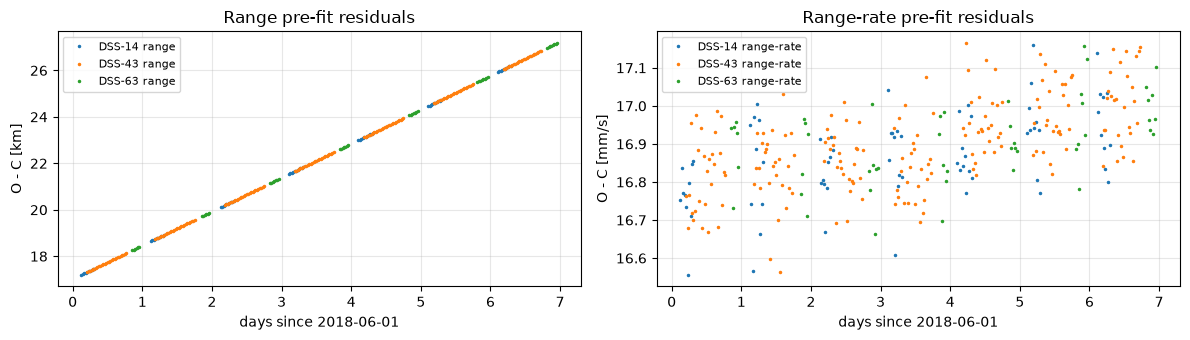

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for model in models:
    t_days = (observed[model.name].meas_time_et - epochs[0]).convert_to(day).values
    if isinstance(model, scb.RangeIdeal):
        ax[0].plot(
            t_days, prefit[model.name].quantity.values, ".", ms=3, label=model.name
        )
    else:
        ax[1].plot(
            t_days,
            prefit[model.name].quantity.convert_to(mm / sec).values,
            ".",
            ms=3,
            label=model.name,
        )
ax[0].set(
    xlabel="days since 2018-06-01", ylabel="O - C [km]", title="Range pre-fit residuals"
)
ax[1].set(
    xlabel="days since 2018-06-01",
    ylabel="O - C [mm/s]",
    title="Range-rate pre-fit residuals",
)
for a in ax:
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()

The a-priori velocity error (1 cm/s per axis) projects onto the line of sight as about 1.7 cm/s. It appears directly as the ~17 mm/s range-rate offset, and it makes the range offset grow by about 1.5 km per day on top of the ~17 km projected position error. The slight trend in range-rate comes from the slow rotation of the line of sight over the week. Both offsets exceed the measurement noise (2 m and 0.1 mm/s) by four orders of magnitude; they are the signal the filter uses to correct the reference.

## 3. Measurement partials

`compute_partials` evaluates $\tilde H_k$ on the reference at each epoch; each row holds the derivatives with respect to the six state components (position, then velocity). For the ideal models they have simple closed forms:

- range: $\partial\rho/\partial\mathbf{r} = \hat{\boldsymbol\rho}$ (the line-of-sight unit vector), $\partial\rho/\partial\mathbf{v} = 0$;
- range-rate: $\partial\dot\rho/\partial\mathbf{v} = \hat{\boldsymbol\rho}$, and $\partial\dot\rho/\partial\mathbf{r}$ is the component of the relative velocity perpendicular to the line of sight, divided by $\rho$, which is small.

A check at the first DSS-43 observation, with the line of sight computed independently from SPICE:

In [5]:
%%capture partials_log
# 🔵 TODO: remove %%capture once compute_partials stops printing progress bars
dss43_range, dss43_rate = models[2], models[3]
t_first = observed["DSS-43 range"].meas_time_et[0:1]  # first observation, as a 1-element EpochArray
H_range = dss43_range.compute_partials(target=reference, epoch_array=t_first)[0]
H_rate = dss43_rate.compute_partials(target=reference, epoch_array=t_first)[0]

In [6]:
relative = (
    reference.get_state(t_first, reference_frame="J2000", origin="SUN").quantity[:3]
    - stations["DSS-43"]
    .get_state(t_first, reference_frame="J2000", origin="SUN")
    .quantity[:3]
)
line_of_sight = (relative / relative.norm()).values

print(f"{'':22s} {'x':>11s} {'y':>11s} {'z':>11s}")
print(f"{'line of sight':22s}", "".join(f"{c:11.7f}" for c in line_of_sight))
print(f"{'range  ∂/∂r':22s}", "".join(f"{c:11.7f}" for c in H_range[:3]))
print(f"{'range  ∂/∂v':22s}", "".join(f"{c:11.7f}" for c in H_range[3:]))
print(f"{'range-rate  ∂/∂v':22s}", "".join(f"{c:11.7f}" for c in H_rate[3:]))
print(f"{'range-rate  ∂/∂r [1/s]':22s}", "".join(f"{c:11.2e}" for c in H_rate[:3]))

                                 x           y           z
line of sight           -0.6794709 -0.4208646 -0.6009927
range  ∂/∂r             -0.6794709 -0.4208646 -0.6009927
range  ∂/∂v              0.0000000  0.0000000  0.0000000
range-rate  ∂/∂v        -0.6794709 -0.4208646 -0.6009927
range-rate  ∂/∂r [1/s]   -5.63e-08   3.90e-08   3.64e-08


## 4. The linearized measurement equation

With $\tilde H_k$ from the measurement model and $\Phi(t_k, t_0)$ from the reference propagation, the linearized equation predicts the pre-fit residuals from the initial deviation alone. The deviation is known here because the data are simulated; the filter estimates it. For DSS-43 range:

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> Need a way to silence all these progress prints!
</div>

In [7]:
%%capture partials_log
# 🔵 TODO: remove %%capture once compute_partials stops printing progress bars
dx0 = (
    x_truth0.quantity
    - reference.get_state(epochs[0], reference_frame="J2000", origin="SUN").quantity
).values

t_obs = observed["DSS-43 range"].meas_time_et
H = dss43_range.compute_partials(target=reference, epoch_array=t_obs)
k_of = scb.Utils.find_date_indices_in_epochs(
    epochs, list(t_obs)
)  # index of each observation in the STM grid
predicted = [sum(h * d for h, d in zip(H[j], Phi[k] @ dx0)) for j, k in enumerate(k_of)]

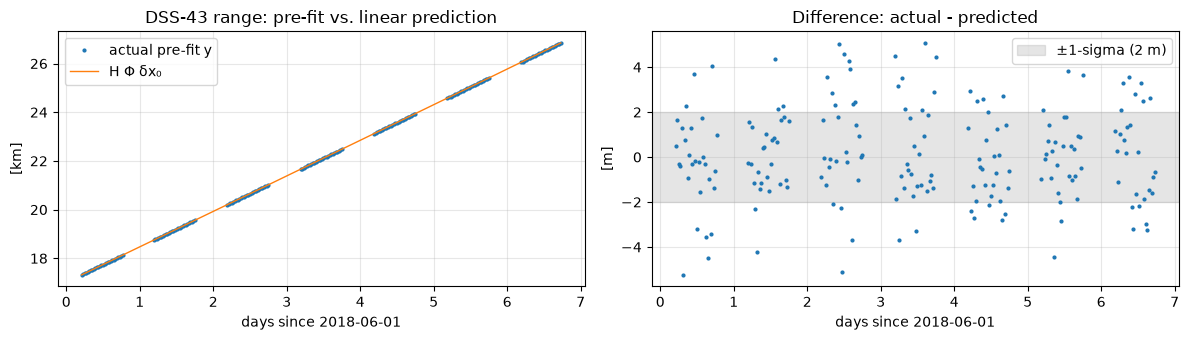

In [8]:
actual = prefit["DSS-43 range"].quantity.values
t_days = (t_obs - epochs[0]).convert_to(day).values
difference_m = [(a - p) * 1e3 for a, p in zip(actual, predicted)]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(t_days, actual, ".", ms=4, label="actual pre-fit y")
ax[0].plot(t_days, predicted, "-", lw=1, label="H Φ δx₀")
ax[0].set(
    xlabel="days since 2018-06-01",
    ylabel="[km]",
    title="DSS-43 range: pre-fit vs. linear prediction",
)
ax[0].legend()
ax[1].plot(t_days, difference_m, ".", ms=4)
ax[1].axhspan(-2, 2, color="gray", alpha=0.2, label="±1-sigma (2 m)")
ax[1].set(
    xlabel="days since 2018-06-01", ylabel="[m]", title="Difference: actual - predicted"
)
ax[1].legend()
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()

The linear prediction reproduces the pre-fit residuals to within the measurement noise: what remains is the simulated noise $\epsilon_k$. Stacking these equations for all observations and solving for $\delta x_0$ in a weighted least-squares sense is the batch filter of [chapter 6](06_first_od_solution.ipynb).

## 5. Packaging the data for the filter

The filters take the models and observations as a `MeasurementSpec`: one spec per dataset (model, observed data, dataset name), combined with `MeasurementSpec.many`. The filter then computes the residuals and partials above at every iteration, on its current reference.

In [9]:
tracking = scb.MeasurementSpec.many(
    *[
        scb.MeasurementSpec(
            model=model, observed_meas=observed[model.name], dataset_name=model.name
        )
        for model in models
    ]
)

for spec in tracking:
    print(f"{spec['dataset_name']:20s} {type(spec['model']).__name__}")

DSS-14 range         RangeIdeal
DSS-14 range-rate    RangeRateIdeal
DSS-43 range         RangeIdeal
DSS-43 range-rate    RangeRateIdeal
DSS-63 range         RangeIdeal
DSS-63 range-rate    RangeRateIdeal


<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> 
</div>
Two related options are set elsewhere:

- **Measurement weights** can be overridden per dataset without changing the models, via `FilterSettings(measurement_sigmas={dataset_name: sigma})` ([chapter 6](06_first_od_solution.ipynb)).
- **Measurement biases** and **station location errors** are state parameters owned by the ground station (`range_bias_<suffix>`, `gs_delta_location_ECEF_<suffix>`; see the parameter table in [chapter 4](04_filter_dynamics.ipynb)). When present in the state, the models include them in $h$ and $\tilde H$ automatically ([chapter 8](08_estimating_more.ipynb)).

## Summary

| Concept | Scarabaeus API |
|---|---|
| Observations | `observed_measurements(file, units=...)` |
| Computed observables on the reference | `computed_measurements(target=reference, epoch_array=...)` |
| Pre-fit residuals | `residuals(observed, computed)` |
| Measurement partials $\tilde H$ | `compute_partials(target, epoch_array)` |
| STM at observation epochs | `Propagator.STM`, `Utils.find_date_indices_in_epochs` |
| Filter input | `MeasurementSpec(model, observed_meas, dataset_name)`, `MeasurementSpec.many` |

**Next:** [6. First OD solution](06_first_od_solution.ipynb) passes the reference propagator from chapter 4 and the `MeasurementSpec` from this chapter to a batch filter and evaluates the solution against the truth.